# Summarize benchmark results

## 0. Imports and path assignments

In [3]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

from matplotlib.colors import LinearSegmentedColormap

In [4]:
data_dir  = Path.cwd() / "results"
fig_dir = Path.cwd() / "figures" / "summary"
fig_dir.mkdir(exist_ok = True)

## 1. Load benchmark results

### Performances

In [5]:
df = pd.read_csv(data_dir / "merged.csv")

data = df[["Method", "Sample_Name", "Total_Reads", "Human_Ratio", "Human_Loss", "Contamination_Rate", "Score"]]
data

,Method,Sample_Name,Total_Reads,Human_Ratio,Human_Loss,Contamination_Rate,Score
0,Xengsort,Mixture 4,20000000,0.7,0.007917,0.000157,0.997515
1,Xengsort,Mixture 4,20000000,0.7,0.007881,0.000155,0.997527
2,Xengsort,Mixture 4,20000000,0.7,0.007886,0.000153,0.997527
3,Xengsort,Mixture 4,20000000,0.7,0.007899,0.000161,0.997518
4,Xengsort,Mixture 4,20000000,0.7,0.007859,0.000158,0.997531
...,...,...,...,...,...,...,...
1723,XenofilteR,Mixture 2,100000000,0.8,0.068153,0.000049,0.979520
1724,XenofilteR,Mixture 2,100000000,0.8,0.068193,0.000047,0.979509
1725,XenofilteR,Mixture 2,100000000,0.8,0.068210,0.000046,0.979505
1726,XenofilteR,Mixture 2,100000000,0.8,0.068171,0.000047,0.979516


### Runtime & Memory

In [7]:
runmem =  pd.read_csv(Path.cwd().parent / "06_runtime_memory" / "results" / "summary.csv")
runmem.columns = [col[0].upper() + col[1:] if col else col for col in runmem.columns]
runmem = runmem.rename(columns={"Peak_rss_gb": "Max_memory_gb"})
runmem = runmem.drop(columns="Unnamed: 0")

## 2. Aggregate results
- Methods
- Across human ratios
- Per dataset
- Per sequencing depths
- Per performance metric
- Runtime & Scalability
- Final Score & Ranking

### Methods

In [8]:
import pandas as pd

method_df = pd.DataFrame({
    "Method": ["bamcmp", "ICRG", "Xengsort", "XenofilteR"],
    "Algorithm": [
        "Dual\nAlignment",
        "Compet.\nAlignment",
        "K-mer",
        "Dual\nAlignment"
    ],
    "Input": ["BAM", "FASTQ", "FASTQ", "BAM"]
})



### Across Human Ratios

In [9]:
mixture_avg = (
    data.groupby(["Method", "Human_Ratio"], as_index=False)
    .agg(Score=("Score", "mean"))
)
mixture_avg["Human_Ratio"] = mixture_avg["Human_Ratio"].astype(str) + "_Score"
mixture_avg = mixture_avg.pivot(index="Method", columns="Human_Ratio", values="Score").reset_index()



### Per dataset

In [10]:
sample_avg = (
    data.groupby(["Method", "Sample_Name"], as_index=False)
    .agg(Score=("Score", "mean"))
    .pivot(index="Method", columns="Sample_Name", values="Score")
)
sample_avg.columns = [f"{col}_Score" for col in sample_avg.columns]
sample_avg = sample_avg.reset_index()



### Per sequencing depth

In [11]:
depth_avg = (
    data.groupby(["Method", "Total_Reads"], as_index=False)
    .agg(Score=("Score", "mean"))
)
depth_avg["Total_Reads"] = depth_avg["Total_Reads"].astype(str) + "_Score"
depth_avg = depth_avg.pivot(index="Method", columns="Total_Reads", values="Score").reset_index()



### Per performance metric

In [12]:
metric_avg = (
    data.groupby("Method", as_index=False)
    .agg(
        Avg_Human_Loss=("Human_Loss", "mean"),
        Avg_Contamination_Rate=("Contamination_Rate", "mean")
    )
)



### Performance Score, Scalability Score, Final Score
- Performance Score = 0.7 * Specificity + 0.3 * Sensitivity 
- Scalability Score = min_max(Runtime) * 0.5 + min_max(Max. Memory)
- Final Score = 0.7 * Performance Score + 0.3 * Scalability Score

In [13]:
score_avg = (
    data.groupby("Method", as_index=False)
    .agg(Avg_Score=("Score", "mean"))
)

import numpy as np

def minmax_scale(x):
    rng = (np.nanmin(x), np.nanmax(x))
    if rng[1] - rng[0] == 0:
        return np.zeros(len(x))
    return (x - rng[0]) / (rng[1] - rng[0])

scores = pd.DataFrame({
    "Method": runmem["Method"],
    "Realtime_Score": 1 - minmax_scale(runmem["Realtime_h"]),
    "Memory_Score": 1 - minmax_scale(runmem["Max_memory_gb"])
})

scores["Runmem_Score"] = scores["Realtime_Score"] * 0.5 + scores["Memory_Score"] * 0.5

scores = scores.merge(score_avg, on="Method", how="left")

scores["Score"] = scores["Avg_Score"] * 0.7 + scores["Runmem_Score"] * 0.3

scores = scores.sort_values("Score", ascending=False).reset_index(drop=True)
scores["Ranking"] = scores.index + 1



In [14]:
final_df = (
    method_df
    .merge(sample_avg, on="Method", how="left")
    .merge(depth_avg, on="Method", how="left")
    .merge(metric_avg, on="Method", how="left")
    .merge(mixture_avg, on="Method", how="left")
    .merge(runmem, on="Method", how="left")
    .merge(scores[["Method", "Score", "Ranking"]], on="Method", how="left")
)

final_df = final_df.sort_values("Ranking").reset_index(drop=True)


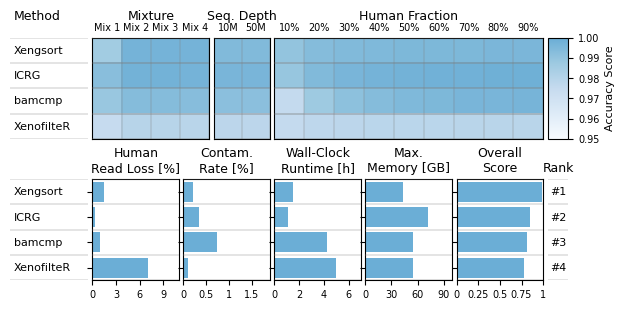

In [16]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

from matplotlib.colors import LinearSegmentedColormap
cmap_wb = LinearSegmentedColormap.from_list("white_blue", ["white", "#2171B5"])



def mm_to_inches(mm):
    return mm / 25.4

df = final_df.copy()
df["Avg_Human_Loss_pct"] = df["Avg_Human_Loss"] * 100
df["Avg_Contamination_Rate_pct"] = df["Avg_Contamination_Rate"] * 100

n = len(df)

mixture_cols = ["Mixture 1_Score", "Mixture 2_Score", "Mixture 3_Score", "Mixture 4_Score"]
depth_cols   = ["20000000_Score", "100000000_Score"]
mixavg_cols  = [f"{x}_Score" for x in ["0.1","0.2","0.3","0.4","0.5","0.6","0.7","0.8","0.9"]]

mixture_labels = {"Mixture 1_Score": "Mix 1", "Mixture 2_Score": "Mix 2",
                    "Mixture 3_Score": "Mix 3", "Mixture 4_Score": "Mix 4"}
depth_labels   = {"20000000_Score": "10M", "100000000_Score": "50M"}
mixavg_labels  = {f"{x}_Score": f"{int(float(x)*100)}%"
                    for x in ["0.1","0.2","0.3","0.4","0.5","0.6","0.7","0.8","0.9"]}

heat_cols = mixture_cols + depth_cols + mixavg_cols
vmin, vmax = 0.95, 1.0
row_y = np.arange(n)
Y_TITLE_R1 = 1.15
Y_TITLE_R2 = 1.05

df_reset = df.reset_index(drop=True)
highlight_idx = df_reset.index[df_reset["Method"].isin(["Xengsort", "bamcmp"])].tolist()
HIGHLIGHT_COLOR = "#D6EAF8"

fig = plt.figure(figsize=(mm_to_inches(183), mm_to_inches(80)))
gs = gridspec.GridSpec(
        2, 17, figure=fig,
        height_ratios=[1, 1], hspace=0.4, wspace=0.15,
        width_ratios=[3] + [1]*15 + [0.8]
    )


def add_title(ax, label, x=0.5, ha="center", y=None):
    if y is None:
        y = Y_TITLE_R1
    ax.text(x, y, label, transform=ax.transAxes,
            ha=ha, va="bottom", fontsize=9, clip_on=False)
        
def add_row_styling(ax, heatmap=False, fill=False):
    for y in np.arange(-0.5, n + 0.5, 1):
        ax.axhline(y, color="grey", linewidth=0.3, zorder=5)
    if fill:
        for idx in highlight_idx:
            ax.axhspan(idx - 0.5, idx + 0.5,
                    color=HIGHLIGHT_COLOR,
                        alpha=0.15 if heatmap else 0.4, zorder=0)
def hide_ax(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_facecolor("none")

    # ── ROW 1: Method column + Heatmaps + Colorbar ──────────────────
ax0 = fig.add_subplot(gs[0, 0])
ax0.set_xlim(0, 1); ax0.set_ylim(n - 0.5, -0.5)
hide_ax(ax0)
add_title(ax0, "Method", x=0.05, ha="left")
for i, row in df_reset.iterrows():
    ax0.text(0.05, i, row["Method"], fontsize=8, va="center", ha="left")
add_row_styling(ax0)

import matplotlib.colors as mcolors


blue = mcolors.to_rgb("#3A8EC4")
    #blue = mcolors.to_rgb("#4292C6")
    #blue = mcolors.to_rgb("#6BAED6")

from matplotlib.colors import LinearSegmentedColormap

blues_9 = ["#f7fbff", "#deebf7", "#c6dbef", "#9ecae1",
        "#6baed6",
           # "#4292c6",
             # "#2171b5",
             #"#08519c",
              # "#08306b"
            ]   # RColorBrewer::brewer.pal(9, "Blues")
            # append + rev(), matching your R pipe

from matplotlib.colors import LinearSegmentedColormap

cmap_wb = LinearSegmentedColormap.from_list("white_lightblue", ["white", "#9ecae1"], N=101)

    #cmap_wb = LinearSegmentedColormap.from_list("white_blue", ["white", blue])
cmap_wb = LinearSegmentedColormap.from_list("navy_blues", blues_9, N=101)




def heatmap_panel(gs_spec, cols, title, label_map):
    ax = fig.add_subplot(gs_spec)
    im = ax.imshow(df[cols].values, cmap=cmap_wb, vmin=vmin, vmax=vmax, aspect="auto")

    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([label_map[c] for c in cols],
                        rotation=0, ha="center", va="bottom", fontsize=7)
    ax.tick_params(axis="x", which="both", length=0)
    ax.set_yticks([])
    ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="grey", linewidth=0.3)
    ax.tick_params(which="minor", length=0)
    add_row_styling(ax, heatmap=True)
    add_title(ax, title)
    return ax, im

ax1, im = heatmap_panel(gs[0, 1:5],  mixture_cols, "Mixture",        mixture_labels)
ax2, _  = heatmap_panel(gs[0, 5:7],  depth_cols,   "Seq. Depth",     depth_labels)
ax3, _  = heatmap_panel(gs[0, 7:16], mixavg_cols,  "Human Fraction", mixavg_labels)

cbar_ax = fig.add_subplot(gs[0, 16])
cbar = fig.colorbar(im, cax=cbar_ax, orientation="vertical")
cbar.set_label("Accuracy Score", fontsize=8)
cbar.set_ticks(np.arange(vmin, vmax, 0.01))
cbar.set_ticklabels([f"{t:.2f}" for t in np.arange(vmin, vmax, 0.01)])
cbar.ax.tick_params(labelsize=7)

# ── ROW 2: Method labels + Bar panels + Rank ─────────────────────
ax_m = fig.add_subplot(gs[1, 0])
ax_m.set_xlim(0, 1); ax_m.set_ylim(n - 0.5, -0.5)
hide_ax(ax_m)
for i, row in df_reset.iterrows():
    ax_m.text(0.05, i, row["Method"], fontsize=8, va="center", ha="left")
add_row_styling(ax_m, fill=False)

from matplotlib.ticker import FuncFormatter

def bar_panel(gs_spec, col, title, color):
    ax = fig.add_subplot(gs_spec)
    ax.barh(row_y, df[col].values, color=color)
    ax.set_yticks(row_y); ax.set_yticklabels([])
    ax.set_ylim(n - 0.5, -0.5)
    ax.tick_params(axis="x", labelrotation=0, labelsize=7)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    add_row_styling(ax, fill=False)
    add_title(ax, title, y=Y_TITLE_R2)
    return ax

bar_color = blues_9[-1]
ax_hrl     = bar_panel(gs[1, 1:4],   "Avg_Human_Loss_pct",         "Human\nRead Loss [%]",    bar_color)
ax_hrl.set_xlim(0, 11)
ax_hrl.set_xticks([0, 3, 6, 9])

ax_contam  = bar_panel(gs[1, 4:7],   "Avg_Contamination_Rate_pct", "Contam.\nRate [%]",       bar_color)
ax_contam.set_xlim(0, 1.9)
ax_contam.set_xticks([0, 0.5, 1, 1.5])

ax_runtime = bar_panel(gs[1, 7:10],  "Realtime_h",                 "Wall-Clock\nRuntime [h]", bar_color)
ax_runtime.set_xlim(0, 7)
ax_runtime.set_xticks([0, 2, 4, 6])

ax_memory  = bar_panel(gs[1, 10:13], "Max_memory_gb",              "Max.\nMemory [GB]",       bar_color)
ax_memory.set_xlim(0, 100)
ax_memory.set_xticks([0, 30, 60, 90])

ax_score   = bar_panel(gs[1, 13:16], "Score",                      "Overall\nScore",          bar_color)
ax_score.set_xlim(0, 1)
ax_score.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax_rank = fig.add_subplot(gs[1, 16])
ax_rank.set_xlim(0, 1); ax_rank.set_ylim(n - 0.5, -0.5)
hide_ax(ax_rank)
for i, rank in zip(row_y, df["Ranking"]):
    ax_rank.text(0.5, i, f"#{int(rank)}", ha="center", va="center",
                fontsize=8)
add_row_styling(ax_rank, fill=False)
add_title(ax_rank, "Rank", y=Y_TITLE_R2)

plt.savefig(fig_dir / "summary_figure.pdf", bbox_inches="tight", dpi=300)
plt.savefig(fig_dir / "summary_figure.png", bbox_inches="tight", dpi=300)


In [16]:
df.to_csv(data_dir / "benchmark_figure_data.csv")